# Лабораторная работа 3

**Вариант 5**

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy import integrate, special, optimize
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import eigs, spsolve

plt.rcParams['figure.figsize'] = (9, 6)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.35

## Задание 1. Параметрически заданная кривая

Эвольвента эллипса:

$$
x(t) = \frac{a^2-b^2}{a}\cos^3 t, \qquad
y(t) = \frac{a^2-b^2}{b}\sin^3 t,
$$

где $a=2$, $b=1$, $t \in [0, 2\pi]$.

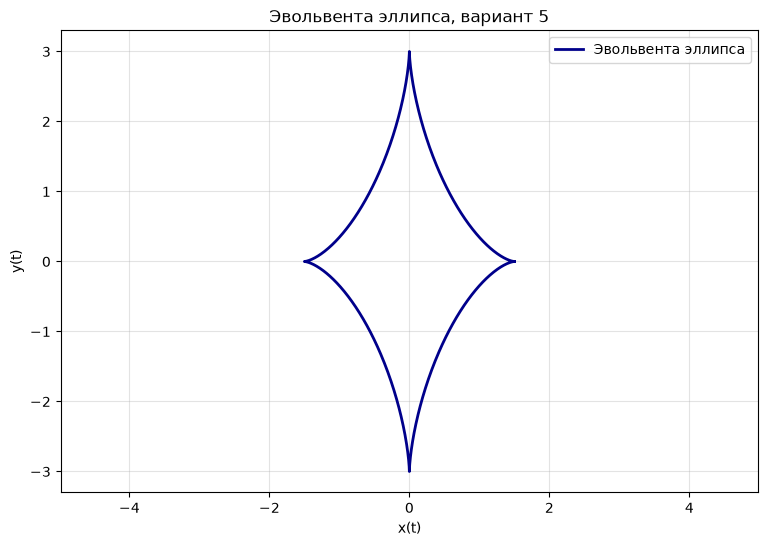

In [2]:
a, b = 2, 1
t = np.linspace(0, 2 * np.pi, 1000)

x_curve = (a**2 - b**2) / a * np.cos(t)**3
y_curve = (a**2 - b**2) / b * np.sin(t)**3

plt.plot(x_curve, y_curve, color='darkblue', linewidth=2, label='Эвольвента эллипса')
plt.xlabel('x(t)')
plt.ylabel('y(t)')
plt.title('Эвольвента эллипса, вариант 5')
plt.axis('equal')
plt.legend()
plt.show()

## Задание 2. Полиномы на одном графике

На отрезке $[-1, 1]$ построены $y(x)=P_5(x)$ и заданная кусочная функция $z(x)$. Дополнительно показаны полиномы Чебышева, Эрмита и Лагерра с индексом 5.

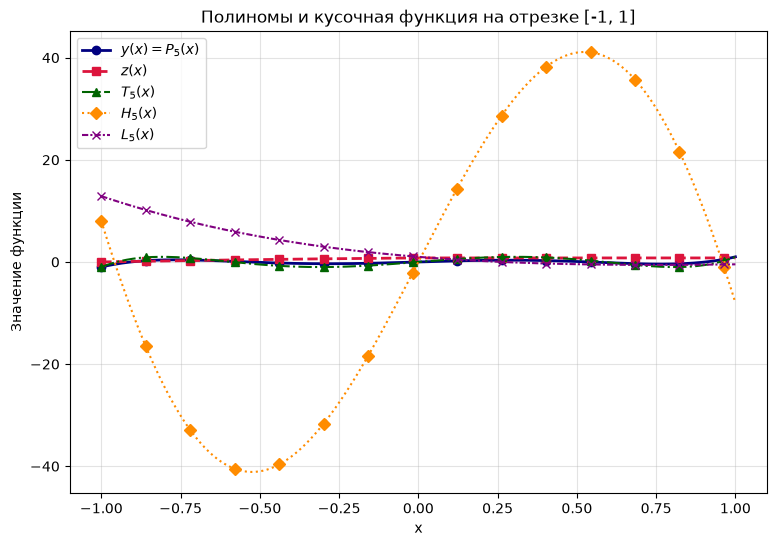

In [3]:
x = np.linspace(-1, 1, 500)

y = np.polynomial.legendre.Legendre.basis(5)(x)
t5 = np.polynomial.chebyshev.Chebyshev.basis(5)(x)
h5 = np.polynomial.hermite.Hermite.basis(5)(x)
l5 = np.polynomial.laguerre.Laguerre.basis(5)(x)
z = np.where(x <= 0, np.arctan(x + 1), np.pi / 4)

plt.plot(x, y, color='navy', linestyle='-', linewidth=2, marker='o', markevery=35, label='$y(x)=P_5(x)$')
plt.plot(x, z, color='crimson', linestyle='--', linewidth=2, marker='s', markevery=35, label='$z(x)$')
plt.plot(x, t5, color='darkgreen', linestyle='-.', marker='^', markevery=35, label='$T_5(x)$')
plt.plot(x, h5, color='darkorange', linestyle=':', marker='D', markevery=35, label='$H_5(x)$')
plt.plot(x, l5, color='purple', linestyle=(0, (3, 1, 1, 1)), marker='x', markevery=35, label='$L_5(x)$')

plt.xlabel('x')
plt.ylabel('Значение функции')
plt.title('Полиномы и кусочная функция на отрезке [-1, 1]')
plt.legend()
plt.show()

## Задание 3. Разреженная матрица и линейная алгебра

Матрица $A$ создается сразу в формате CSR без промежуточной плотной матрицы. Для варианта 5 используется матрица со скриншота лабораторной работы 2.

In [4]:
def create_sparse_matrix(N):
    """Создает разреженную матрицу варианта 5 непосредственно в формате CSR."""
    if N != 7:
        raise ValueError('Для матрицы варианта 5 N должен быть равен 7')

    rows = [
        [0, 1], [1, 2], [2, 3], list(range(N)),
        [4, 5], [5, 6], [6],
    ]
    values = [
        [-7, 4], [-6, 4], [-5, 4], [-4] * N,
        [-3, 4], [-2, 4], [-1],
    ]

    row_indices = []
    column_indices = []
    data = []
    for row_number, (columns, row_values) in enumerate(zip(rows, values)):
        row_indices.extend([row_number] * len(columns))
        column_indices.extend(columns)
        data.extend(row_values)

    return csr_matrix((data, (row_indices, column_indices)), shape=(N, N), dtype=float)


def matrix_task_2(A):
    """Основные операции задания 2 лабораторной работы 2."""
    dense_A = A.toarray()
    print('Матрица A:')
    print(dense_A)
    print('Размер:', A.shape)
    print('Число ненулевых элементов:', A.nnz)
    print('Ранг:', np.linalg.matrix_rank(dense_A))
    print('Определитель:', np.linalg.det(dense_A))
    print('Норма:', np.linalg.norm(dense_A))
    print('Обратная матрица:')
    print(np.linalg.inv(dense_A))

    right_side = np.arange(1, A.shape[0] + 1, dtype=float)
    solution = np.linalg.solve(dense_A, right_side)
    print('Решение системы A @ u = [1, ..., 7]:')
    print(solution)
    return solution

N = 7
A = create_sparse_matrix(N)
solution = matrix_task_2(A)

Матрица A:
[[-7.  4.  0.  0.  0.  0.  0.]
 [ 0. -6.  4.  0.  0.  0.  0.]
 [ 0.  0. -5.  4.  0.  0.  0.]
 [-4. -4. -4. -4. -4. -4. -4.]
 [ 0.  0.  0.  0. -3.  4.  0.]
 [ 0.  0.  0.  0.  0. -2.  4.]
 [ 0.  0.  0.  0.  0.  0. -1.]]
Размер: (7, 7)
Число ненулевых элементов: 18
Ранг: 7
Определитель: -13295.999999999985
Норма: 17.776388834631177
Обратная матрица:
[[-0.12635379 -0.06498195 -0.02888087 -0.02888087  0.03850782  0.13477738
   0.65463297]
 [ 0.02888087 -0.11371841 -0.05054152 -0.05054152  0.06738869  0.23586041
   1.1456077 ]
 [ 0.0433213   0.07942238 -0.07581227 -0.07581227  0.10108303  0.35379061
   1.71841155]
 [ 0.05415162  0.09927798  0.15523466 -0.09476534  0.12635379  0.44223827
   2.14801444]
 [-0.         -0.         -0.         -0.         -0.33333333 -0.66666667
  -2.66666667]
 [-0.         -0.         -0.         -0.         -0.         -0.5
  -2.        ]
 [-0.         -0.         -0.         -0.         -0.         -0.
  -1.        ]]
Решение системы A @ u = [1, ...

In [5]:
def sparse_matrix_task_2(A):
    right_side = np.arange(1, A.shape[0] + 1, dtype=float)
    sparse_solution = spsolve(A, right_side)
    eigenvalues = eigs(A, k=2, which='LM', return_eigenvectors=False)

    print('Решение разреженной системы A @ u = [1, ..., 7]:')
    print(sparse_solution)
    print('Два собственных значения с наибольшими по модулю:')
    print(eigenvalues)
    return sparse_solution, eigenvalues

sparse_solution, eigenvalues = sparse_matrix_task_2(A)

Решение разреженной системы A @ u = [1, ..., 7]:
[  5.12515042   9.21901324  14.32851986  18.66064982 -24.33333333
 -17.          -7.        ]
Два собственных значения с наибольшими по модулю:
[-8.17789878+2.22685682j -8.17789878-2.22685682j]


## Задание 4. Минимум функции F(a)

Для варианта 5:

$$F(a)=\int_2^5 \operatorname{erf}(ax)J_0(ax)J_1\left(\frac{x}{a}\right)\,dx, \qquad a\in[1,6].$$

a_min = 1.28062136
F(a_min) = -0.30326346


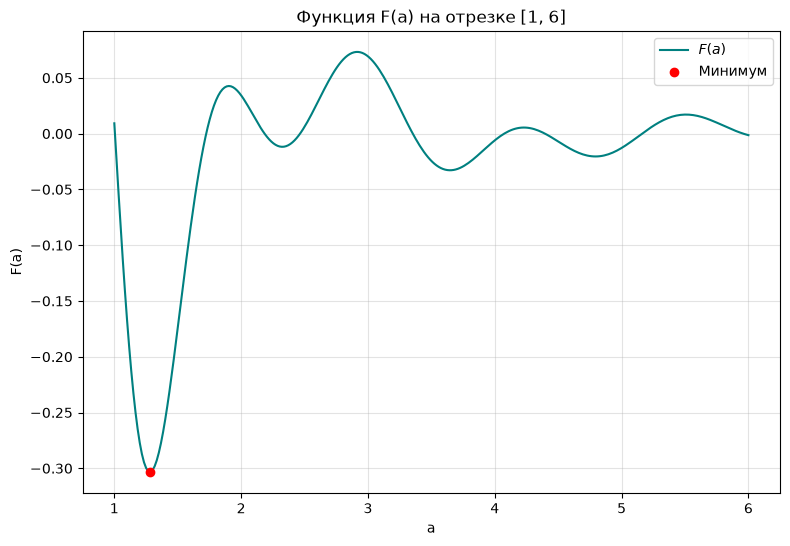

In [12]:
def F(a):
    def integrand(x):
        return special.erf(a * x) * special.jv(0, a * x) * special.jv(1, x / a)

    value, error = integrate.quad(integrand, 2, 5)
    return value

a_values = np.linspace(1, 6, 300)
F_values = np.array([F(a_value) for a_value in a_values])

i = np.argmin(F_values)
l = a_values[max(i - 1, 0)]
r = a_values[min(i + 1, len(a_values) - 1)]
minimum_result = optimize.minimize_scalar(F, bounds=(l, r), method='bounded')

print(f'a_min = {minimum_result.x:.8f}')
print(f'F(a_min) = {minimum_result.fun:.8f}')

plt.plot(a_values, F_values, color='teal', label='$F(a)$')
plt.scatter([minimum_result.x], [minimum_result.fun], color='red', zorder=3, label='Минимум')
plt.xlabel('a')
plt.ylabel('F(a)')
plt.title('Функция F(a) на отрезке [1, 6]')
plt.legend()
plt.show()

## Задание 5. Локальный минимум функции двух переменных

Для варианта 5:

$$f(x,y)=2x^4-xy^2+5x^2+y^4.$$

Точка локального минимума: [2.46290425e-06 5.35045921e-03]
Значение функции в точке: 7.793517280798623e-10


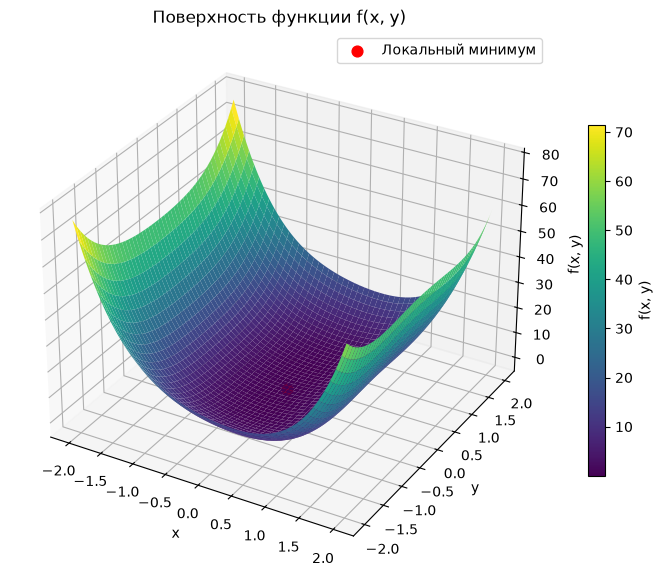

In [13]:
def f(point):
    x_value, y_value = point
    return 2 * x_value**4 - x_value * y_value**2 + 5 * x_value**2 + y_value**4

minimum_2d = optimize.minimize(f, x0=np.array([0.5, 0.5]), method='BFGS')
minimum_point = minimum_2d.x
print('Точка локального минимума:', minimum_point)
print('Значение функции в точке:', minimum_2d.fun)

x_grid = np.linspace(-2, 2, 250)
y_grid = np.linspace(-2, 2, 250)
X, Y = np.meshgrid(x_grid, y_grid)
Z = 2 * X**4 - X * Y**2 + 5 * X**2 + Y**4

figure = plt.figure(figsize=(10, 7))
axis_3d = figure.add_subplot(111, projection='3d')
surface = axis_3d.plot_surface(X, Y, Z, cmap='viridis', linewidth=0, antialiased=True)
axis_3d.scatter(minimum_point[0], minimum_point[1], minimum_2d.fun, color='red', s=60, label='Локальный минимум')
axis_3d.set_xlabel('x')
axis_3d.set_ylabel('y')
axis_3d.set_zlabel('f(x, y)')
axis_3d.set_title('Поверхность функции f(x, y)')
axis_3d.legend()
figure.colorbar(surface, ax=axis_3d, shrink=0.65, label='f(x, y)')
plt.show()

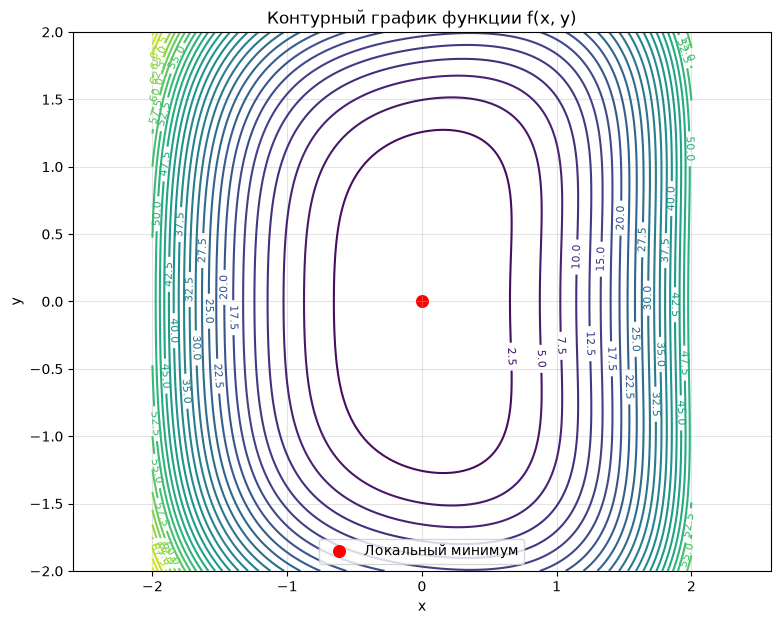

In [14]:
plt.figure(figsize=(9, 7))
contour = plt.contour(X, Y, Z, levels=30, cmap='viridis')
plt.clabel(contour, inline=True, fontsize=8)
plt.scatter(minimum_point[0], minimum_point[1], color='red', s=70, label='Локальный минимум')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Контурный график функции f(x, y)')
plt.axis('equal')
plt.legend()
plt.show()